In [1]:
import numpy as np
from proflib import load_profdata
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path
import re

In [2]:
plt.rcParams.update({
    # --- 图尺寸 ---
    "figure.figsize": (1.6, 1.6),  # 每张图大小，可根据内容微调
    "figure.dpi": 170,

    # --- 字体 ---
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "cm",   # 数学字体与 LaTeX 一致
    "font.size": 7,             # IEEE/ACM 通常 7pt；Nature 通常 8pt
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "legend.fontsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,

    # --- 线条和标记 ---
    "lines.linewidth": 0.8,
    "lines.markersize": 3,
    "axes.linewidth": 0.5,  # 坐标轴线条
    "grid.linewidth": 0.3,

    # --- 图例 ---
    "legend.frameon": False,
    "legend.handlelength": 1.5,

    # --- 刻度 ---
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "xtick.minor.size": 1.2,
    "ytick.minor.size": 1.2,
    "xtick.major.width": 0.4,
    "ytick.major.width": 0.4,

    # --- 版面 ---
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.01,

    "image.cmap": "cividis",      # 连续型默认
    "axes.prop_cycle": plt.cycler("color", plt.cm.tab10.colors),  # 折线色
})

# Overall

In [7]:
all_data = []
for file in sorted(Path('build/').glob('boom_l_4.T*/prof*/linux.bin.out')):
    data = file.with_suffix('.out').read_text()
    items = re.findall(r'cycle=(\d+), last_freq=([0-9.]+) kHz, freq=([0-9.]+) kHz', data)
    total_cycles, _, freq = items[-1]
    total_cycles = int(total_cycles)
    freq = float(freq)
    design = file.parent.parent.stem
    threads = int(file.parent.parent.suffix[2:])
    if file.parent.name == 'prof':
        kind = 'no pgo'
    if file.parent.name == 'prof.pgo':
        kind = 'pgo'
    data = {
        'design': design,
        'threads': threads,
        'total_cycles': total_cycles,
        'freq': freq,
        'kind': kind,
    }
    all_data.append(data)
df = pd.DataFrame(all_data)
df

,design,threads,total_cycles,freq,kind
0,boom_l_4,1,10000000,18.7241,no pgo
1,boom_l_4,1,10000000,17.6563,pgo
2,boom_l_4,10,10000000,85.8457,no pgo
3,boom_l_4,10,10000000,146.2680,pgo
4,boom_l_4,11,10000000,98.6907,no pgo
5,boom_l_4,11,10000000,131.4100,pgo
6,boom_l_4,12,10000000,122.2230,no pgo
7,boom_l_4,12,10000000,140.6760,pgo
8,boom_l_4,2,10000000,34.2446,no pgo
9,boom_l_4,2,10000000,54.8258,pgo


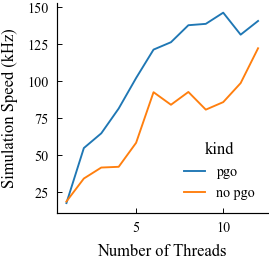

In [8]:
sns.lineplot(df, x='threads', y='freq', hue='kind', hue_order=['pgo', 'no pgo'])
plt.ylabel('Simulation Speed (kHz)')
plt.xlabel('Number of Threads')
sns.despine()

# Case Study

In [15]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from proflib import load_profdata

In [ ]:
data = load_profdata('build/boom_l_2.T10/prof/linux.bin')

In [23]:
def convert_data(data):
    step_elapsed = data.rdtsc_avg()
    step_pivot = np.concatenate([
        step_elapsed[:, [2]].sum(axis=-1, keepdims=True),
        step_elapsed[:, [1, 3]].sum(axis=-1, keepdims=True),
        step_elapsed[:, [0, 4]].sum(axis=-1, keepdims=True),
    ], axis=-1)
    step_names = ['eval', 'idle', 'comm']
    return step_pivot, step_names

In [24]:
# plt.figure(figsize=(5, 5))
step_ticks, step_names = convert_data(data)
step_ticks

array([[ 9723.9722474,  5955.115674 ,  2560.5676792],
       [ 4835.0716316, 10927.553197 ,  2475.5409188],
       [ 1149.8291598, 14593.5989924,  2498.841099 ],
       [  120.8377574, 15613.4516308,  2507.5031668],
       [   64.6409384, 15660.6857598,  2516.9067958],
       [ 5837.1420016,  9930.9164824,  2473.8431826],
       [ 4023.439449 , 11721.3625544,  2496.6890862],
       [ 3424.0536268, 12348.631462 ,  2467.8603664],
       [ 5035.7496362, 10711.0843474,  2494.5744814],
       [13726.0228706,  1891.8688702,  2622.991874 ]])

In [25]:
def plot_stack_bar(data, include_avg=False, colors=None):
    stack = np.cumsum(data, axis=1)
    xlabels = [f'T{i+1}' for i in range(data.shape[0])]
    x = np.arange(data.shape[0])
    if include_avg:
        avg = data.mean(axis=0)
        data = np.concatenate([data, avg[None]], axis=0)
        xsep = x[-1] + 1.25 / 2
        x = np.concatenate([x, [x[-1] + 1.25]])
        plt.axvline(xsep, color='k', lw=0.5)
        xlabels.append('Avg.')
    stack = np.cumsum(data, axis=1)
    data_pct = data / data.sum(axis=1, keepdims=True)
    handles = []
    for i in range(data.shape[1]):
        bottom = np.zeros(data.shape[0]) if i == 0 else stack[:, i-1]
        color = colors[i] if colors else None
        h = plt.bar(x, data[:, i], width=0.5, bottom=bottom, color=color)
        for j in range(data.shape[0]):
            plt.text(
                x[j],
                bottom[j] + data[:, i][j] / 2,
                f'{data_pct[:, i][j]:.0%}',
                ha='center',
                va='center',
                color='k',
                fontsize=5.5,
            )
        handles.append(h)
    plt.xticks(x, xlabels)
    return handles

Text(0, 0.5, 'CPU Utilization')

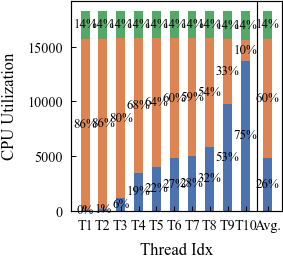

In [26]:
argidx = np.argsort(step_ticks[:, 0])
step_mean = step_ticks[argidx]
cmap = sns.color_palette("deep", 10)
handles = plot_stack_bar(step_mean, colors=cmap, include_avg=True)
plt.xlabel('Thread Idx')
plt.ylabel('CPU Utilization')